# 0. Importing the libraries and the Dataset

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from imblearn.over_sampling import SMOTE
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix
from collections import Counter
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, root_mean_squared_error
from catboost import CatBoostRegressor

In [2]:
df = pd.read_excel(r"C:\Users\Dell\Documents\Elevator BTP\elevator_fault_dataset_full.xlsx")
df.head()

,Timestamp,Motor_Current,Motor_Voltage,Vibration_Level,Speed,Cabin_Position,Cabin_Acceleration,Cabin_Deceleration,Door_Operation_Time,Braking_Force,...,Control_System_Delay,Frequency_of_Emergency_Stops,Button_Press_Logs,Door_Obstruction_Events,Overload_Events,Health_Indices,RUL,Fault_State,Fault_Category,Fault_Severity
0,2020-01-01 00:00:00,22.289903,241.253222,1.393233,3.519079,19,0.349191,0.358643,5.747832,112.280046,...,0.097096,3,61.037683,0,0,171.975594,893.941155,1,Door Failure,Minor
1,2020-01-01 01:00:00,25.240487,236.078046,0.090303,2.226921,9,0.260127,0.266565,7.552277,142.770141,...,0.075588,1,15.653676,0,0,150.250886,2130.455491,0,Brake Failure,Critical
2,2020-01-01 02:00:00,32.769471,432.220975,0.932987,2.523211,20,0.291057,0.161099,7.703547,98.016876,...,0.091237,3,25.963784,0,0,164.327588,2472.445475,0,Motor Malfunction,Minor
3,2020-01-01 03:00:00,34.913962,645.108627,0.490413,4.910428,20,0.439094,0.214058,8.335525,75.588623,...,0.128085,2,25.590539,0,0,142.256458,1753.632090,0,Motor Malfunction,Moderate
4,2020-01-01 04:00:00,27.799073,224.451891,0.844176,5.188226,20,0.566116,0.365294,4.717031,95.882924,...,0.112181,2,41.910883,0,0,89.765157,2399.361778,0,Sensor Error,Critical


In [3]:
df.columns

Index(['Timestamp', 'Motor_Current', 'Motor_Voltage', 'Vibration_Level',
       'Speed', 'Cabin_Position', 'Cabin_Acceleration', 'Cabin_Deceleration',
       'Door_Operation_Time', 'Braking_Force', 'Rope_Tension',
       'Guide_Rail_Condition_Index', 'Pulley_Wear', 'Lubrication_Levels',
       'Power_Consumption', 'Battery_Health', 'Voltage_Fluctuations',
       'Current_Harmonics', 'Ambient_Temperature', 'Humidity', 'Dust_Levels',
       'External_Vibration_Levels', 'Load', 'Passenger_Count',
       'Number_of_Trips', 'Stop_Frequency', 'Travel_Distance',
       'Call_Waiting_Time', 'Fault_Logs', 'Maintenance_History',
       'Component_Age', 'Last_Serviced_Days_Ago', 'MTTF', 'Signal_Noise',
       'Temperature_Gradient', 'Door_Sensor_Readings', 'Control_System_Delay',
       'Frequency_of_Emergency_Stops', 'Button_Press_Logs',
       'Door_Obstruction_Events', 'Overload_Events', 'Health_Indices', 'RUL',
       'Fault_State', 'Fault_Category', 'Fault_Severity'],
      dtype='object')

In [4]:
df.describe()

,Timestamp,Motor_Current,Motor_Voltage,Vibration_Level,Speed,Cabin_Position,Cabin_Acceleration,Cabin_Deceleration,Door_Operation_Time,Braking_Force,...,Temperature_Gradient,Door_Sensor_Readings,Control_System_Delay,Frequency_of_Emergency_Stops,Button_Press_Logs,Door_Obstruction_Events,Overload_Events,Health_Indices,RUL,Fault_State
count,43081,43081.000000,43081.000000,43081.000000,43081.000000,43081.000000,43081.000000,43081.000000,43081.000000,43081.000000,...,43081.000000,43081.000000,43081.000000,43081.000000,43081.000000,43081.000000,43081.000000,43081.000000,43081.000000,43081.000000
mean,2022-06-16 12:00:00,20.007145,431.579785,1.061568,4.137727,12.211509,0.423724,0.424355,6.006516,93.867087,...,4.254711,2.004485,0.106113,1.204731,40.114333,0.120958,0.051717,165.580733,1993.225441,0.049001
min,2020-01-01 00:00:00,-6.001927,193.426993,-1.046984,-0.006227,1.000000,-0.004989,-0.005564,1.135067,11.398771,...,-0.416884,0.560706,0.011504,0.000000,-1.993226,0.000000,0.000000,44.303186,234.390523,0.000000
25%,2021-03-24 18:00:00,12.845171,239.566444,0.678029,2.912413,8.000000,0.310947,0.310805,4.322978,57.863897,...,3.119447,1.545725,0.081561,0.000000,26.681656,0.000000,0.000000,130.728130,1374.578523,0.000000
50%,2022-06-16 12:00:00,19.322315,443.246319,1.016829,4.069830,13.000000,0.415335,0.416363,6.044557,92.398963,...,4.161882,2.043467,0.104923,1.000000,39.385686,0.000000,0.000000,167.692429,1983.553645,0.000000
75%,2023-09-08 06:00:00,25.944461,565.513853,1.396938,5.222795,17.000000,0.527032,0.527909,7.562396,122.245096,...,5.294993,2.528876,0.130326,2.000000,51.385049,0.000000,0.000000,203.894267,2534.122077,0.000000
max,2024-11-30 00:00:00,67.075258,785.982800,3.528198,10.791246,20.000000,1.125637,1.113787,14.154409,265.367196,...,11.376517,3.937312,0.245835,4.000000,113.396210,2.000000,1.000000,377.893803,4959.749191,1.000000
std,NaN,8.946545,157.420244,0.520863,1.613444,5.494766,0.155926,0.156237,2.164365,39.289883,...,1.565204,0.668839,0.035506,1.163954,16.460090,0.383101,0.221457,52.455462,757.830885,0.215872


# 1. Univariate Analysis

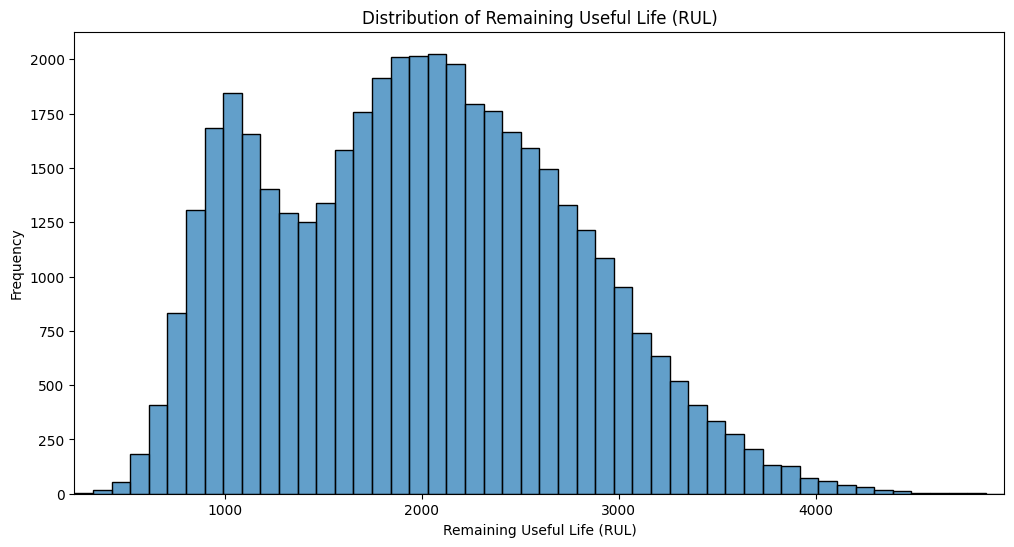

In [5]:
plt.figure(figsize=(12, 6))
sns.histplot(
    data=df['RUL'],
    bins=50,
    edgecolor='black',
    alpha=0.7
)
plt.title('Distribution of Remaining Useful Life (RUL)')
plt.xlabel('Remaining Useful Life (RUL)')
plt.ylabel('Frequency')
plt.xlim(df['RUL'].min(), df['RUL'].max())
plt.show()

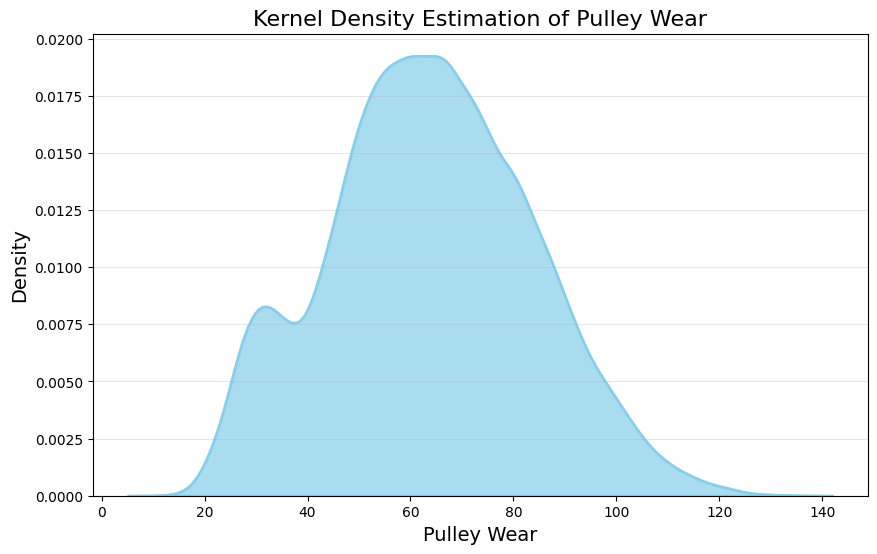

In [6]:
plt.figure(figsize=(10, 6))

# Use seaborn for a smooth KDE plot to estimate the probability density function
sns.kdeplot(df['Pulley_Wear'], fill=True, color='skyblue', alpha=0.7, linewidth=2)

# Set labels and title
plt.title('Kernel Density Estimation of Pulley Wear', fontsize=16)
plt.xlabel('Pulley Wear', fontsize=14)
plt.ylabel('Density', fontsize=14)
plt.grid(axis='y', alpha=0.3)
plt.show()

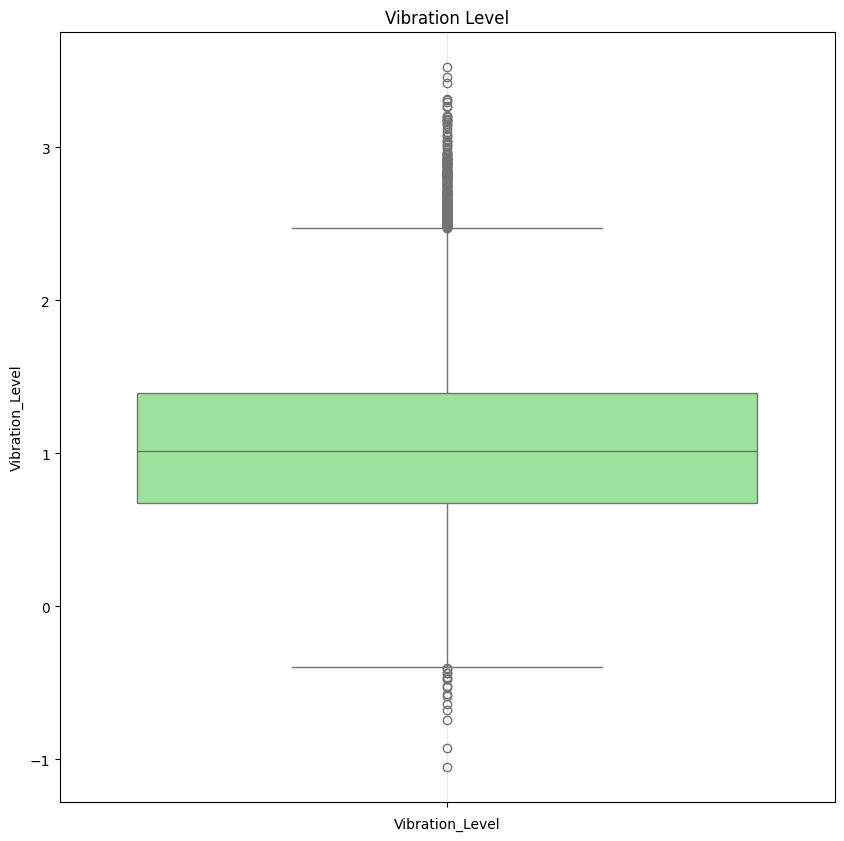

In [7]:
plt.figure(figsize=(10, 10))
sns.boxplot(
    data=df['Vibration_Level'],
    color='lightgreen'
)
plt.title('Vibration Level')
plt.xlabel('Vibration_Level')
plt.grid(axis='x', alpha=0.3)
plt.show()

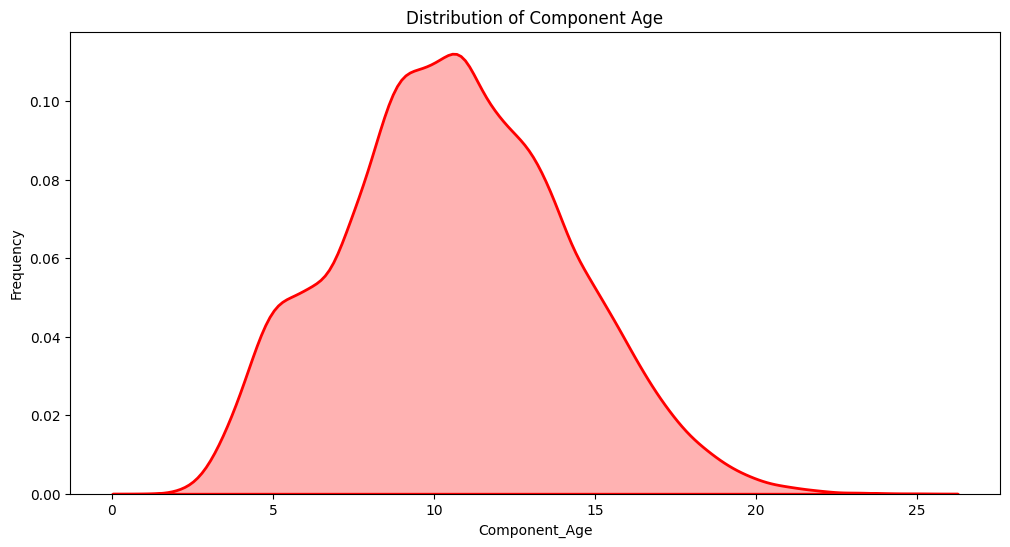

In [8]:
plt.figure(figsize=(12, 6))
sns.kdeplot(df['Component_Age'], fill=True, color='red', alpha=0.3, linewidth=2)
plt.title('Distribution of Component Age')
plt.xlabel('Component_Age')
plt.ylabel('Frequency')
plt.show()

# 2. Multivariate Analysis 

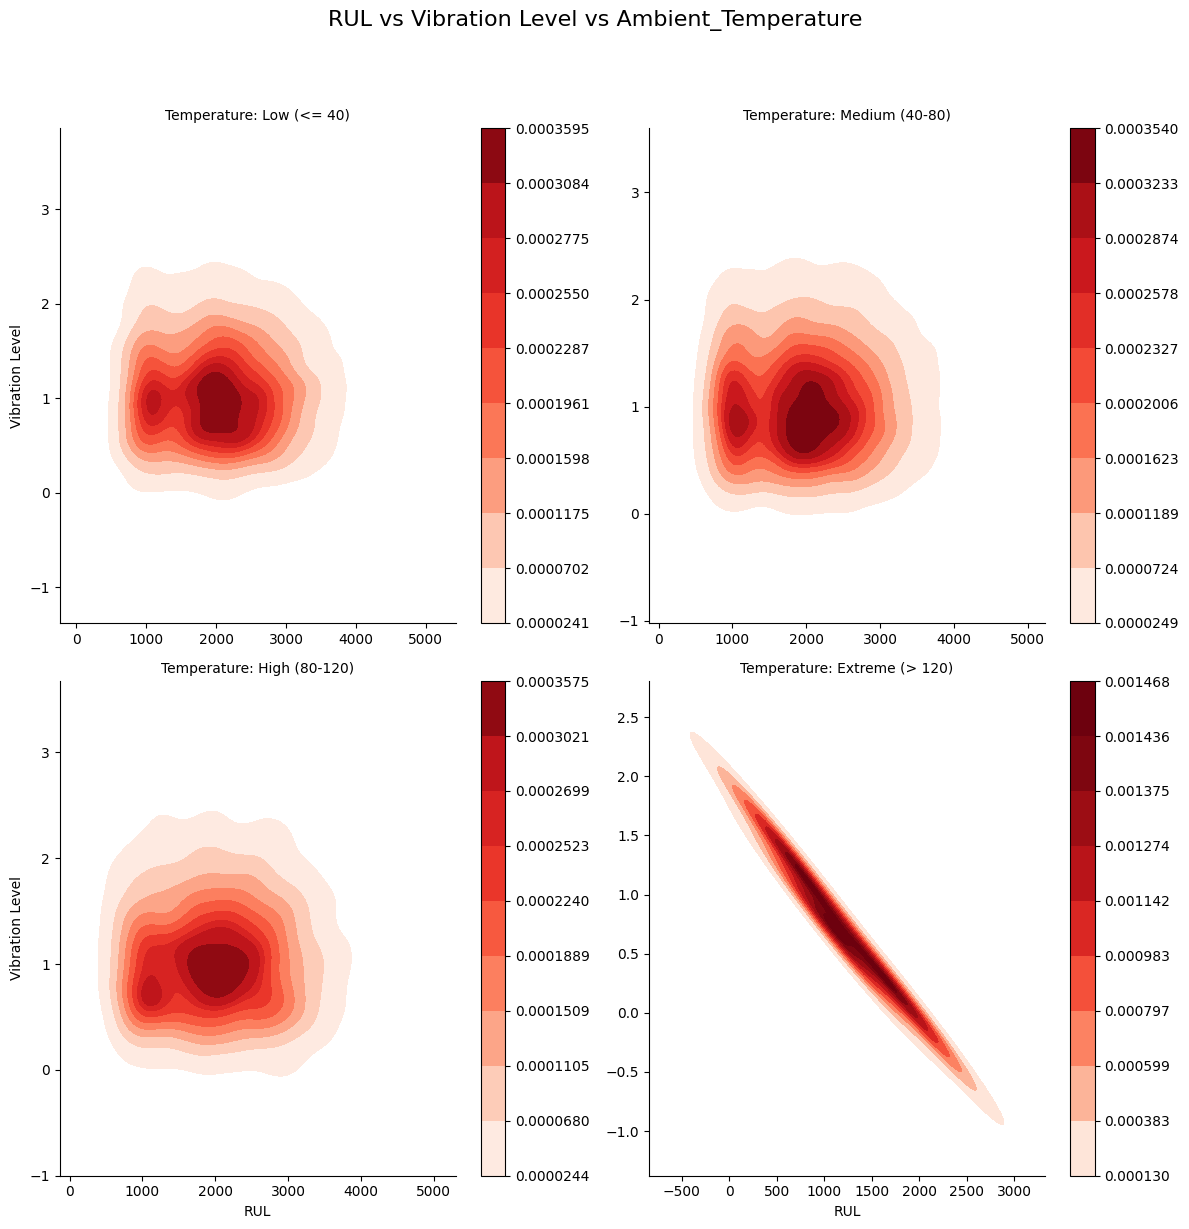

In [9]:
bins = [0, 40, 80, 120, df['Ambient_Temperature'].max() + 1]
labels = ['Low (<= 40)', 'Medium (40-80)', 'High (80-120)', 'Extreme (> 120)']

# Segment the continuous Ambient_Temperature data into categories
df['Temp_Category'] = pd.cut(
    df['Ambient_Temperature'], 
    bins=bins, 
    labels=labels, 
    right=True, 
    include_lowest=True
)
# Determine the order of categories for consistent plotting sequence
category_order = ['Low (<= 40)', 'Medium (40-80)', 'High (80-120)', 'Extreme (> 120)']
category_order = [c for c in category_order if c in df['Temp_Category'].cat.categories]

# Create the FacetGrid object
g = sns.FacetGrid(
    df, 
    col='Temp_Category', 
    col_order=category_order,
    col_wrap=2, # Plots will wrap to 2 columns for readability
    sharex=False, 
    sharey=False,
    height=6
)

g.map_dataframe(
    sns.kdeplot, 
    x='RUL', 
    y='Vibration_Level', 
    fill=True, 
    cbar=True, 
    cmap="Reds"
)

# Set final titles and adjust layout
g.set_axis_labels("RUL", "Vibration Level")
g.set_titles(col_template="Temperature: {col_name}")
plt.suptitle('RUL vs Vibration Level vs Ambient_Temperature', y=1.02, fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

In [10]:
df.columns

Index(['Timestamp', 'Motor_Current', 'Motor_Voltage', 'Vibration_Level',
       'Speed', 'Cabin_Position', 'Cabin_Acceleration', 'Cabin_Deceleration',
       'Door_Operation_Time', 'Braking_Force', 'Rope_Tension',
       'Guide_Rail_Condition_Index', 'Pulley_Wear', 'Lubrication_Levels',
       'Power_Consumption', 'Battery_Health', 'Voltage_Fluctuations',
       'Current_Harmonics', 'Ambient_Temperature', 'Humidity', 'Dust_Levels',
       'External_Vibration_Levels', 'Load', 'Passenger_Count',
       'Number_of_Trips', 'Stop_Frequency', 'Travel_Distance',
       'Call_Waiting_Time', 'Fault_Logs', 'Maintenance_History',
       'Component_Age', 'Last_Serviced_Days_Ago', 'MTTF', 'Signal_Noise',
       'Temperature_Gradient', 'Door_Sensor_Readings', 'Control_System_Delay',
       'Frequency_of_Emergency_Stops', 'Button_Press_Logs',
       'Door_Obstruction_Events', 'Overload_Events', 'Health_Indices', 'RUL',
       'Fault_State', 'Fault_Category', 'Fault_Severity', 'Temp_Category'],
      

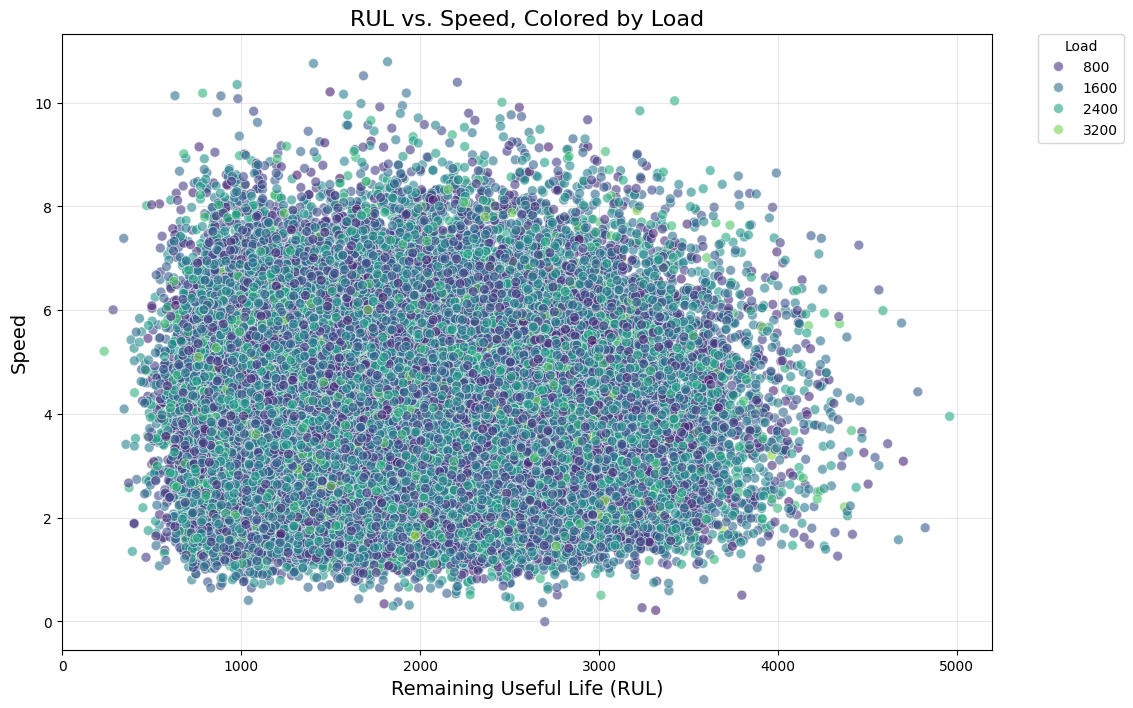

In [ ]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=df, 
    x='RUL', 
    y='Speed', 
    hue='Load', 
    palette='viridis', 
    alpha=0.6,
    s=50 
)
plt.title('RUL vs. Speed vs Load', fontsize=16)
plt.xlabel('Remaining Useful Life (RUL)', fontsize=14)
plt.ylabel('Speed', fontsize=14)
plt.legend(title='Load', bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.grid(alpha=0.3)
plt.show()

In [17]:
df.columns 

Index(['Timestamp', 'Motor_Current', 'Motor_Voltage', 'Vibration_Level',
       'Speed', 'Cabin_Position', 'Cabin_Acceleration', 'Cabin_Deceleration',
       'Door_Operation_Time', 'Braking_Force', 'Rope_Tension',
       'Guide_Rail_Condition_Index', 'Pulley_Wear', 'Lubrication_Levels',
       'Power_Consumption', 'Battery_Health', 'Voltage_Fluctuations',
       'Current_Harmonics', 'Ambient_Temperature', 'Humidity', 'Dust_Levels',
       'External_Vibration_Levels', 'Load', 'Passenger_Count',
       'Number_of_Trips', 'Stop_Frequency', 'Travel_Distance',
       'Call_Waiting_Time', 'Fault_Logs', 'Maintenance_History',
       'Component_Age', 'Last_Serviced_Days_Ago', 'MTTF', 'Signal_Noise',
       'Temperature_Gradient', 'Door_Sensor_Readings', 'Control_System_Delay',
       'Frequency_of_Emergency_Stops', 'Button_Press_Logs',
       'Door_Obstruction_Events', 'Overload_Events', 'Health_Indices', 'RUL',
       'Fault_State', 'Fault_Category', 'Fault_Severity', 'Temp_Category'],
      

In [31]:
df[['Timestamp', 'Last_Serviced_Days_Ago', 'Maintenance_History', 'Fault_Category', 'Fault_State']].head(20)

,Timestamp,Last_Serviced_Days_Ago,Maintenance_History,Fault_Category,Fault_State
0,2020-01-01 00:00:00,59.873162,0,Door Failure,1
1,2020-01-01 01:00:00,41.039249,2,Brake Failure,0
2,2020-01-01 02:00:00,39.840995,0,Motor Malfunction,0
3,2020-01-01 03:00:00,15.153118,1,Motor Malfunction,0
4,2020-01-01 04:00:00,38.376884,3,Sensor Error,0
5,2020-01-01 05:00:00,18.500289,2,Door Failure,0
6,2020-01-01 06:00:00,77.036176,2,Sensor Error,0
7,2020-01-01 07:00:00,63.585801,2,Motor Malfunction,0
8,2020-01-01 08:00:00,93.045388,0,Door Failure,0
9,2020-01-01 09:00:00,8.720152,2,Motor Malfunction,0


In [3]:
df['Age_Difference'] = df['Component_Age'].diff()
is_new_component = (df['Age_Difference'] < 0) | (df.index == df.index.min())
df['Component_ID_Proxy'] = is_new_component.cumsum()
df = df.drop(columns=['Age_Difference'])
print("Component_ID_Proxy successfully created.")

Component_ID_Proxy successfully created.


In [36]:
df[['Timestamp', 'Component_Age', 'Component_ID_Proxy']].head(10)

,Timestamp,Component_Age,Component_ID_Proxy
0,2020-01-01 00:00:00,6.456381,1
1,2020-01-01 01:00:00,10.267459,1
2,2020-01-01 02:00:00,14.140011,1
3,2020-01-01 03:00:00,12.100756,2
4,2020-01-01 04:00:00,15.132594,2
5,2020-01-01 05:00:00,12.369007,3
6,2020-01-01 06:00:00,3.690595,4
7,2020-01-01 07:00:00,10.398882,4
8,2020-01-01 08:00:00,11.948543,4
9,2020-01-01 09:00:00,13.271210,4


In [4]:
HIGH_SPEED_THRESHOLD = 6

df['High_Speed_Event'] = np.where(df['Speed'] > HIGH_SPEED_THRESHOLD, 1, 0)

# Calculte the High_Speed_Hours (Cumulative Count) 

# Calculate the running total of events, resetting for each component proxy
df['High_Speed_Hours'] = df.groupby('Component_ID_Proxy')['High_Speed_Event'].cumsum()


# Calculate Load_Accumulation (Cumulative Sum) 

# Calculate the running total of 'Load', resetting for each component proxy
df['Load_Accumulation'] = df.groupby('Component_ID_Proxy')['Load'].cumsum()

# Remove the temporary event marker column
df = df.drop(columns=['High_Speed_Event'])

print("Successfully created 'High_Speed_Hours' and 'Load_Accumulation'")

Successfully created 'High_Speed_Hours' and 'Load_Accumulation'


In [5]:
df[['Timestamp', 'Speed', 'Load', 'Component_ID_Proxy', 'High_Speed_Hours', 'Load_Accumulation']].head(10)

,Timestamp,Speed,Load,Component_ID_Proxy,High_Speed_Hours,Load_Accumulation
0,2020-01-01 00:00:00,3.519079,845.186023,1,0,845.186023
1,2020-01-01 01:00:00,2.226921,1078.418306,1,0,1923.604329
2,2020-01-01 02:00:00,2.523211,2355.043882,1,0,4278.648211
3,2020-01-01 03:00:00,4.910428,785.277646,2,0,785.277646
4,2020-01-01 04:00:00,5.188226,2011.447371,2,0,2796.725017
5,2020-01-01 05:00:00,5.585850,792.534794,3,0,792.534794
6,2020-01-01 06:00:00,7.387495,2194.666453,4,1,2194.666453
7,2020-01-01 07:00:00,5.980737,1507.556116,4,1,3702.222569
8,2020-01-01 08:00:00,3.079548,1021.416495,4,1,4723.639064
9,2020-01-01 09:00:00,5.094043,1455.645279,4,1,6179.284342


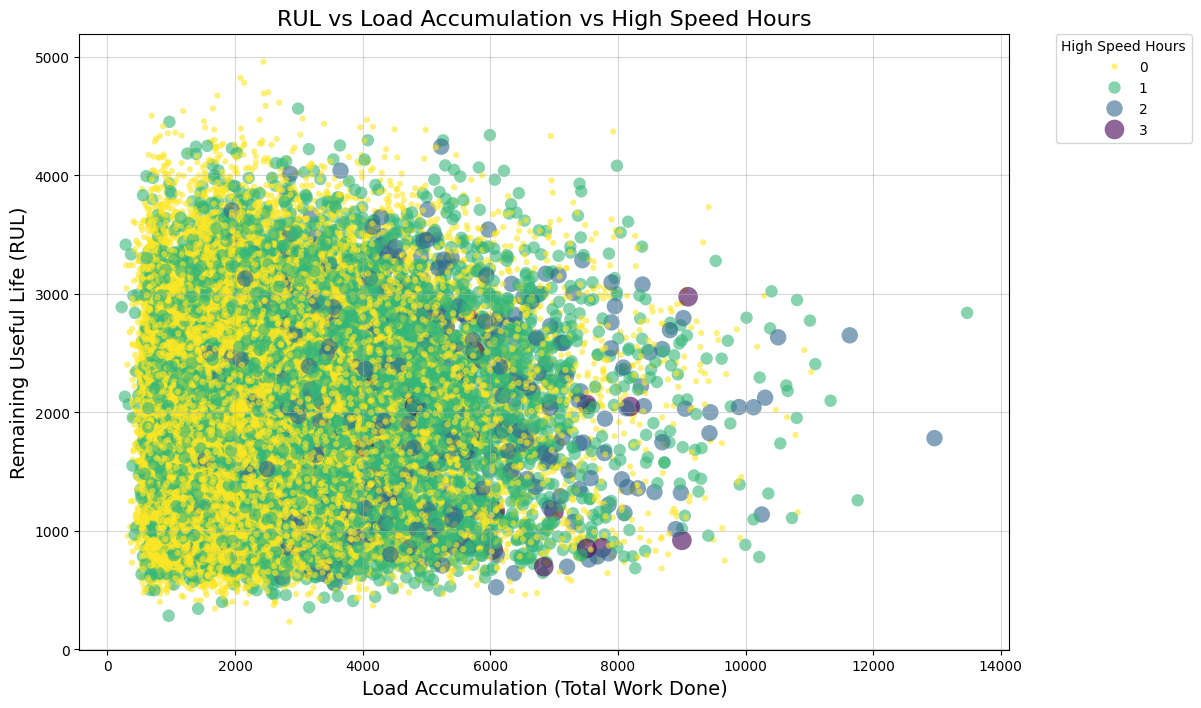

In [41]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=df, 
    x='Load_Accumulation', 
    y='RUL', 
    hue='High_Speed_Hours', 
    palette='viridis_r', 
    size='High_Speed_Hours', 
    sizes=(20, 200), 
    alpha=0.6,
    linewidth=0
)
plt.title('RUL vs Load Accumulation vs High Speed Hours', fontsize=16)
plt.xlabel('Load Accumulation (Total Work Done)', fontsize=14)
plt.ylabel('Remaining Useful Life (RUL)', fontsize=14)
plt.legend(title='High Speed Hours', bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.grid(axis='both', alpha=0.5)
plt.show()

In [6]:
df['Pulley_Wear_Accumulated'] = df.groupby('Component_ID_Proxy')['Pulley_Wear'].cumsum()

print("Successfully created the 'Pulley_Wear_Accumulated' cumulative feature")

Successfully created the 'Pulley_Wear_Accumulated' cumulative feature


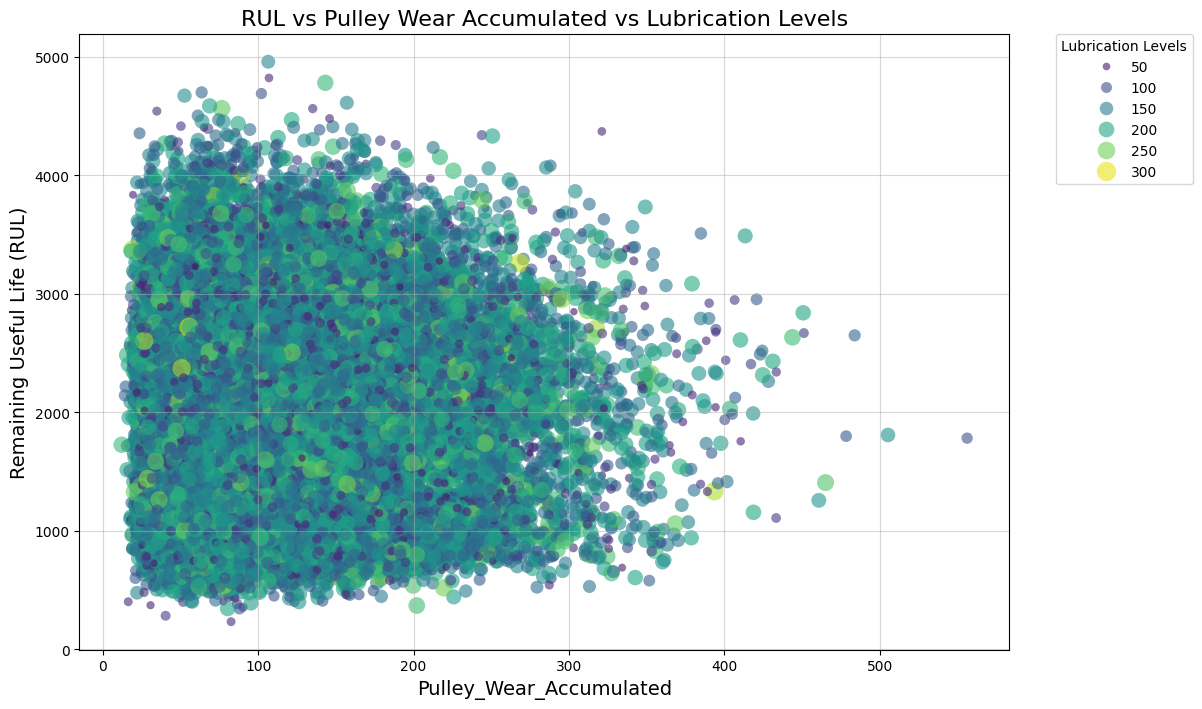

In [45]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=df, 
    x='Pulley_Wear_Accumulated', 
    y='RUL', 
    hue='Lubrication_Levels', 
    palette='viridis', 
    size='Lubrication_Levels', 
    sizes=(20, 200),
    alpha=0.6,
    linewidth=0
)
plt.title('RUL vs Pulley Wear Accumulated vs Lubrication Levels', fontsize=16)
plt.xlabel('Pulley_Wear_Accumulated', fontsize=14)
plt.ylabel('Remaining Useful Life (RUL)', fontsize=14)
plt.legend(title='Lubrication Levels', bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.grid(axis='both', alpha=0.5)
plt.show()

In [51]:
df[['Timestamp', 'Speed', 'Load', 'Component_ID_Proxy', 'High_Speed_Hours', 'Load_Accumulation', 'Pulley_Wear_Accumulated']].head(10)

,Timestamp,Speed,Load,Component_ID_Proxy,High_Speed_Hours,Load_Accumulation,Pulley_Wear_Accumulated
0,2020-01-01 00:00:00,3.519079,845.186023,1,0,845.186023,84.152230
1,2020-01-01 01:00:00,2.226921,1078.418306,1,0,1923.604329,130.980306
2,2020-01-01 02:00:00,2.523211,2355.043882,1,0,4278.648211,189.880795
3,2020-01-01 03:00:00,4.910428,785.277646,2,0,785.277646,65.480344
4,2020-01-01 04:00:00,5.188226,2011.447371,2,0,2796.725017,143.115920
5,2020-01-01 05:00:00,5.585850,792.534794,3,0,792.534794,63.198625
6,2020-01-01 06:00:00,7.387495,2194.666453,4,1,2194.666453,85.884710
7,2020-01-01 07:00:00,5.980737,1507.556116,4,1,3702.222569,172.592268
8,2020-01-01 08:00:00,3.079548,1021.416495,4,1,4723.639064,225.723813
9,2020-01-01 09:00:00,5.094043,1455.645279,4,1,6179.284342,273.588690


In [53]:
df.to_excel(r"C:\Users\Dell\Documents\Elevator BTP\elevator_fault_dataset_enhanced.xlsx", index=False)

In [49]:
df.columns 

Index(['Timestamp', 'Motor_Current', 'Motor_Voltage', 'Vibration_Level',
       'Speed', 'Cabin_Position', 'Cabin_Acceleration', 'Cabin_Deceleration',
       'Door_Operation_Time', 'Braking_Force', 'Rope_Tension',
       'Guide_Rail_Condition_Index', 'Pulley_Wear', 'Lubrication_Levels',
       'Power_Consumption', 'Battery_Health', 'Voltage_Fluctuations',
       'Current_Harmonics', 'Ambient_Temperature', 'Humidity', 'Dust_Levels',
       'External_Vibration_Levels', 'Load', 'Passenger_Count',
       'Number_of_Trips', 'Stop_Frequency', 'Travel_Distance',
       'Call_Waiting_Time', 'Fault_Logs', 'Maintenance_History',
       'Component_Age', 'Last_Serviced_Days_Ago', 'MTTF', 'Signal_Noise',
       'Temperature_Gradient', 'Door_Sensor_Readings', 'Control_System_Delay',
       'Frequency_of_Emergency_Stops', 'Button_Press_Logs',
       'Door_Obstruction_Events', 'Overload_Events', 'Health_Indices', 'RUL',
       'Fault_State', 'Fault_Category', 'Fault_Severity', 'Temp_Category',
       

In [102]:
df1 = df[['Timestamp', 'Motor_Current', 'Motor_Voltage', 'Vibration_Level',
       'Speed', 'Cabin_Position', 'Cabin_Acceleration', 'Cabin_Deceleration',
       'Door_Operation_Time', 'Braking_Force', 'Rope_Tension',
       'Guide_Rail_Condition_Index', 'Pulley_Wear', 'Lubrication_Levels',
       'Power_Consumption', 'Battery_Health', 'Voltage_Fluctuations',
       'Current_Harmonics', 'Ambient_Temperature', 'Humidity', 'Dust_Levels',
       'External_Vibration_Levels', 'Load', 'Passenger_Count',
       'Number_of_Trips', 'Stop_Frequency', 'Travel_Distance',
       'Call_Waiting_Time', 'Fault_Logs', 'Maintenance_History',
       'Component_Age', 'Last_Serviced_Days_Ago', 'MTTF', 'Signal_Noise',
       'Temperature_Gradient', 'Door_Sensor_Readings', 'Control_System_Delay',
       'Frequency_of_Emergency_Stops', 'Button_Press_Logs',
       'Door_Obstruction_Events', 'Overload_Events', 'Health_Indices', 'RUL',
       'Fault_State', 
       'Component_ID_Proxy', 'High_Speed_Hours', 'Load_Accumulation',
       'Pulley_Wear_Accumulated']]
corr = df1.corr()
corr_positive = corr['RUL'].sort_values(ascending=False)
corr_negative = corr['RUL'].sort_values(ascending=True)

In [104]:
corr_negative 

Rope_Tension                   -0.007783
Number_of_Trips                -0.006477
Passenger_Count                -0.006369
Humidity                       -0.006253
Lubrication_Levels             -0.005759
Fault_Logs                     -0.005712
Ambient_Temperature            -0.005651
Voltage_Fluctuations           -0.004544
Signal_Noise                   -0.004360
Travel_Distance                -0.004279
Cabin_Position                 -0.004170
Door_Operation_Time            -0.003830
External_Vibration_Levels      -0.003633
Stop_Frequency                 -0.003345
Guide_Rail_Condition_Index     -0.003153
Frequency_of_Emergency_Stops   -0.002831
Braking_Force                  -0.002475
Current_Harmonics              -0.002316
Temperature_Gradient           -0.001895
Motor_Voltage                  -0.001781
Overload_Events                -0.001422
Call_Waiting_Time              -0.001303
Control_System_Delay           -0.000269
Door_Sensor_Readings           -0.000091
Pulley_Wear     

In [9]:
df_new = df[['RUL', 'Load_Accumulation', 'Pulley_Wear_Accumulated', 'Cabin_Acceleration', 'Load', 'MTTF', 'Battery_Health', 'Fault_State', 'Last_Serviced_Days_Ago', 'Speed',
'Rope_Tension', 'Number_of_Trips', 'Passenger_Count', 'Humidity', 'Lubrication_Levels', 'Fault_Logs', 'Ambient_Temperature', 'Voltage_Fluctuations', 'Signal_Noise', 'Travel_Distance' ]]

# 3. Model Training  

(i) Baseline Regression Model (Without the Temp_Category)

In [10]:
# Define the target variable
TARGET_COLUMN = 'RUL'

# Combine the top positive and negative correlation features
BASE_FEATURES = [
    'Load_Accumulation', 'Pulley_Wear_Accumulated', 'Cabin_Acceleration', 
    'Load', 'MTTF', 'Battery_Health', 'Fault_State', 
    'Last_Serviced_Days_Ago', 'Speed', 'Rope_Tension', 
    'Number_of_Trips', 'Passenger_Count', 'Humidity', 
    'Lubrication_Levels', 'Fault_Logs', 'Ambient_Temperature', 
    'Voltage_Fluctuations', 'Signal_Noise', 'Travel_Distance' 
]

In [11]:
X = df_new[BASE_FEATURES]
y = df_new[TARGET_COLUMN]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [12]:
# Initialize and fit the scaler on the training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Transform the test data
X_test_scaled = scaler.transform(X_test)

In [13]:
# Initialize the model
rfr = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1, max_depth=15, min_samples_leaf=5)

# Train the model
rfr.fit(X_train_scaled, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,15
,min_samples_split,2
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [14]:
# Predict on the test set
y_pred = rfr.predict(X_test_scaled)

# Calculate metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("--- MODEL EVALUATION ---")
print(f"Baseline Model: Random Forest Regressor")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared Score (R2): {r2}")

# Feature Importance
feature_importances = pd.Series(rfr.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\n--- TOP 10 FEATURE IMPORTANCE ---")
print(feature_importances.head(10).to_markdown())

--- MODEL EVALUATION ---
Baseline Model: Random Forest Regressor
Root Mean Squared Error (RMSE): 757.59
R-squared Score (R2): -0.0032816004322162584

--- TOP 10 FEATURE IMPORTANCE ---
|                        |         0 |
|:-----------------------|----------:|
| Signal_Noise           | 0.0605379 |
| MTTF                   | 0.0598716 |
| Last_Serviced_Days_Ago | 0.0596123 |
| Rope_Tension           | 0.0595271 |
| Passenger_Count        | 0.0593043 |
| Number_of_Trips        | 0.0590347 |
| Cabin_Acceleration     | 0.0589631 |
| Voltage_Fluctuations   | 0.0585108 |
| Humidity               | 0.0581925 |
| Ambient_Temperature    | 0.0579283 |


(ii) Linear Regression Model - Training on the Temp_Category, Extreme i.e. >120

In [116]:
# DEFINE SEGMENTATION THRESHOLD
EXTREME_TEMP_THRESHOLD = 120

# PREPARE THE DATA FRAME FOR SEGMENTATION 
SEGMENT_FEATURES = ['Load_Accumulation', 'Ambient_Temperature', 'RUL']

# Create a clean working copy of the original DataFrame
df_segment = df.copy().dropna(subset=SEGMENT_FEATURES)


# SEGMENT THE DATA
df_extreme = df_segment[df_segment['Ambient_Temperature'] > EXTREME_TEMP_THRESHOLD].copy()

if df_extreme.shape[0] == 0:
    print("\n--- SEGMENTED MODEL (Extreme Temp) ---")
    print("Error: No data points found where Ambient_Temperature > 120. Cannot train model.")
else:
    X_extreme = df_extreme[['Load_Accumulation']]
    y_extreme = df_extreme['RUL']

    # Splitting the segment data (Optional, but good for validation)
    X_extreme_train, X_extreme_test, y_extreme_train, y_extreme_test = train_test_split(
        X_extreme, y_extreme, test_size=0.2, random_state=42
    )

    # --- 4. TRAIN LINEAR REGRESSION MODEL ---
    lr_model = LinearRegression()
    lr_model.fit(X_extreme_train, y_extreme_train)

    # --- 5. EVALUATION ---
    y_extreme_pred = lr_model.predict(X_extreme_test)

    # Calculate metrics
    mse_extreme = mean_squared_error(y_extreme_test, y_extreme_pred)
    rmse_extreme = np.sqrt(mse_extreme)
    r2_extreme = r2_score(y_extreme_test, y_extreme_pred)

    print("\n--- SEGMENTED MODEL (Extreme Temp > 120) ---")
    print(f"Model Type: Linear Regression (RUL ~ Load_Accumulation)")
    print(f"Data Points in Segment: {df_extreme.shape[0]}")
    print(f"Root Mean Squared Error (RMSE): {rmse_extreme:.2f}")
    print(f"R-squared Score (R2): {r2_extreme:.2f}")
    print(f"Model Coefficient (Slope): {lr_model.coef_[0]:.4f}")


--- SEGMENTED MODEL (Extreme Temp > 120) ---
Model Type: Linear Regression (RUL ~ Load_Accumulation)
Data Points in Segment: 3
Root Mean Squared Error (RMSE): 29271.90
R-squared Score (R2): nan
Model Coefficient (Slope): -5.7414


c:\Users\Dell\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_regression.py:1283: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


In [9]:
# Define the target variable
TARGET_COLUMN = 'RUL'

# Combine the top positive and negative correlation features
BASE_FEATURES = [
    'Load_Accumulation', 'Pulley_Wear_Accumulated', 'Cabin_Acceleration', 
    'Load', 'MTTF', 'Battery_Health', 'Fault_State', 
    'Last_Serviced_Days_Ago', 'Speed', 'Rope_Tension', 
    'Number_of_Trips', 'Passenger_Count', 'Humidity', 
    'Lubrication_Levels', 'Fault_Logs', 'Ambient_Temperature', 
    'Voltage_Fluctuations', 'Signal_Noise', 'Travel_Distance' 
]

X = df_new[BASE_FEATURES]
y = df_new[TARGET_COLUMN]

# -------------------------
# 2. Train-test split
# -------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# -------------------------
# 3. Preprocessing
# -------------------------
numeric_features = BASE_FEATURES

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features)
    ]
)

# -------------------------
# 4. Baseline Models
# -------------------------
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=200, random_state=42
    )
}

for name, model in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    print(f"\n===== {name} =====")
    print("MAE :", mean_absolute_error(y_test, y_pred))
    print("RMSE:", root_mean_squared_error(y_test, y_pred))
    print("R²  :", r2_score(y_test, y_pred))


===== Linear Regression =====
MAE : 623.3364108687988
RMSE: 756.4722403029773
R²  : -0.00031120822074615084

===== Random Forest Regressor =====
MAE : 627.8943439904258
RMSE: 761.8687400627794
R²  : -0.014634097002291124


(iii) Tree Models - CatBoostRegressor, LightGBM, XGBoost

In [11]:
pip install catboost lightgbm xgboost

   ---------------------------------------- 0.0/102.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/102.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/102.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/102.4 MB ? eta -:--:--
   ---------------------------------------- 0.5/102.4 MB 692.6 kB/s eta 0:02:28
   ---------------------------------------- 1.0/102.4 MB 1.1 MB/s eta 0:01:31
    --------------------------------------- 1.3/102.4 MB 1.3 MB/s eta 0:01:18
    --------------------------------------- 1.3/102.4 MB 1.3 MB/s eta 0:01:18
    --------------------------------------- 1.3/102.4 MB 1.3 MB/s eta 0:01:18
    --------------------------------------- 1.6/102.4 MB 928.4 kB/s eta 0:01:49
    --------------------------------------- 1.6/102.4 MB 928.4 kB/s eta 0:01:49
    --------------------------------------- 1.6/102.4 MB 928.4 kB/s eta 0:01:49
    --------------------------------------- 1.8/102.4 MB 775.5 kB/s eta 0:02:10
    


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
X = df[BASE_FEATURES]
y = df[TARGET_COLUMN]

In [ ]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [13]:
cat_model = CatBoostRegressor(
    depth=8,
    learning_rate=0.05,
    iterations=1000,
    loss_function='RMSE',
    verbose=100
)

cat_model.fit(X_train, y_train)

y_pred_cat = cat_model.predict(X_test)

print("=== CatBoost ===")
print("MAE :", mean_absolute_error(y_test, y_pred_cat))
print("RMSE:", root_mean_squared_error(y_test, y_pred_cat))
print("R²  :", r2_score(y_test, y_pred_cat))

0:	learn: 757.9431949	total: 183ms	remaining: 3m 3s
100:	learn: 737.6913259	total: 2.21s	remaining: 19.7s
200:	learn: 720.2540765	total: 4.21s	remaining: 16.7s
300:	learn: 703.4487697	total: 6.12s	remaining: 14.2s
400:	learn: 685.6540898	total: 8.16s	remaining: 12.2s
500:	learn: 669.1594690	total: 10.1s	remaining: 10.1s
600:	learn: 652.8107336	total: 12.1s	remaining: 8.03s
700:	learn: 637.6281426	total: 14.2s	remaining: 6.04s
800:	learn: 622.9835972	total: 16.1s	remaining: 3.99s
900:	learn: 609.1274137	total: 17.9s	remaining: 1.97s
999:	learn: 596.0925993	total: 19.8s	remaining: 0us
=== CatBoost ===
MAE : 630.8730774410633
RMSE: 765.1908704348627
R²  : -0.023502017805435704


In [15]:
import lightgbm as lgb

lgb_model = lgb.LGBMRegressor(
    n_estimators=800,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=64
)

lgb_model.fit(X_train, y_train)
y_pred_lgb = lgb_model.predict(X_test)

print("=== LightGBM ===")
print("MAE :", mean_absolute_error(y_test, y_pred_lgb))
print("RMSE:", root_mean_squared_error(y_test, y_pred_lgb))
print("R²  :", r2_score(y_test, y_pred_lgb))

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003831 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4347
[LightGBM] [Info] Number of data points in the train set: 34464, number of used features: 19
[LightGBM] [Info] Start training from score 1995.260543
=== LightGBM ===
MAE : 635.5953425306459
RMSE: 771.6450313316699
R²  : -0.04084071367491049


In [17]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=800,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.9,
    colsample_bytree=0.9
)

xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

print("=== XGBoost ===")
print("MAE :", mean_absolute_error(y_test, y_pred_xgb))
print("RMSE:", root_mean_squared_error(y_test, y_pred_xgb))
print("R²  :", r2_score(y_test, y_pred_xgb))

=== XGBoost ===
MAE : 641.2180118346752
RMSE: 779.4330566513806
R²  : -0.061956641118855904


In [18]:
df.head()

,Timestamp,Motor_Current,Motor_Voltage,Vibration_Level,Speed,Cabin_Position,Cabin_Acceleration,Cabin_Deceleration,Door_Operation_Time,Braking_Force,...,Overload_Events,Health_Indices,RUL,Fault_State,Fault_Category,Fault_Severity,Component_ID_Proxy,High_Speed_Hours,Load_Accumulation,Pulley_Wear_Accumulated
0,2020-01-01 00:00:00,22.289903,241.253222,1.393233,3.519079,19,0.349191,0.358643,5.747832,112.280046,...,0,171.975594,893.941155,1,Door Failure,Minor,1,0,845.186023,84.152230
1,2020-01-01 01:00:00,25.240487,236.078046,0.090303,2.226921,9,0.260127,0.266565,7.552277,142.770141,...,0,150.250886,2130.455491,0,Brake Failure,Critical,1,0,1923.604329,130.980306
2,2020-01-01 02:00:00,32.769471,432.220975,0.932987,2.523211,20,0.291057,0.161099,7.703547,98.016876,...,0,164.327588,2472.445475,0,Motor Malfunction,Minor,1,0,4278.648211,189.880795
3,2020-01-01 03:00:00,34.913962,645.108627,0.490413,4.910428,20,0.439094,0.214058,8.335525,75.588623,...,0,142.256458,1753.632090,0,Motor Malfunction,Moderate,2,0,785.277646,65.480344
4,2020-01-01 04:00:00,27.799073,224.451891,0.844176,5.188226,20,0.566116,0.365294,4.717031,95.882924,...,0,89.765157,2399.361778,0,Sensor Error,Critical,2,0,2796.725017,143.115920
